# UPSC Essay Evaluation Workflow

Here, we analyze an essay and return a **structured evaluation output**.

### Why Structured Output?
We use a model configured with structured outputs (via Pydantic schema) because standard text generation is non-deterministic: while it may work 8 out of 10 times, the remaining times it might fail schema expectations (e.g., returning an integer score as a string like `"8/10"` or producing invalid JSON). Structured outputs guarantee strict type validation and consistent field formats.

In [19]:
from typing import TypedDict, Optional, Annotated
from pydantic import BaseModel, Field
from dotenv import load_dotenv

import operator

from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI

In [20]:
load_dotenv()

True

In [21]:
model = ChatGoogleGenerativeAI(model='gemini-flash-lite-latest')

In [22]:
class EvaluationSchema(BaseModel):

    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10', ge=0, le=10)

In [23]:
structured_model = model.with_structured_output(EvaluationSchema)

In [24]:
essay = """
## Role of India in Artificial Intelligence (AI)

India is playing an increasingly important role in the development and growth of Artificial Intelligence (AI). As one of the world's largest technology hubs, India has a strong pool of skilled engineers, researchers, and IT professionals contributing to AI innovation.

The Indian government is also promoting AI through initiatives like IndiaAI Mission, which aims to improve AI research, develop infrastructure, and encourage startups. AI is being used in various sectors, including healthcare, education, agriculture, banking, and transportation. For example, AI helps doctors detect diseases, supports farmers with better crop predictions, and makes digital services more efficient.

India also has the opportunity to develop AI solutions for its diverse population by supporting multiple Indian languages and solving local challenges. However, issues like data privacy, unemployment, and ethical AI development must be addressed.

In conclusion, India has the potential to become a global leader in Artificial Intelligence. With proper investment, innovation, and skilled talent, India can use AI to drive economic growth and improve people's lives.

"""

In [25]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
structured_model.invoke(prompt)

EvaluationSchema(feedback='The essay is well-written, clear, and demonstrates a strong command of the English language. The vocabulary is appropriate for discussing technology and policy, and the sentence structures vary effectively. The arguments flow logically from an introduction to the role of human capital, government initiatives, specific applications, challenges, and a solid conclusion. Grammar and punctuation are accurate throughout.', score=9)

In [26]:
class UPSCState(TypedDict):
    essay: str

    language_feedback: Optional[str]
    analysis_feedback: Optional[str]
    clarity_feedback: Optional[str]
    
    overall_feedback: Optional[str]
    individual_scores: Annotated[list[int], operator.add]
    avg_score: Optional[float]

### `individual_scores`

When multiple parallel nodes concurrently update the **same state key**, LangGraph requires a **reducer function** to merge their updates safely without overwriting:

- **The Problem:** By default, LangGraph overwrites state keys with the latest returned value. If multiple parallel nodes write to the same key simultaneously, updates conflict or get lost.
- **The Solution:** We use `Annotated` with `operator.add`:
  ```python
  individual_scores: Annotated[list[int], operator.add]
  ```
- **How It Works:** Each parallel evaluator returns its score wrapped in a list (e.g., `[8]`, `[7]`, `[9]`). The `operator.add` reducer automatically concatenates them into a single consolidated list: `[8, 7, 9]`.

In [27]:
# 1. Evaluator Nodes

def evaluate_language(state: UPSCState) -> dict:
    prompt = f"Evaluate the language quality, grammar, vocabulary, and expression of the following essay. Provide constructive feedback and assign a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {
        "language_feedback": result.feedback,
        "individual_scores": [result.score]
    }


def evaluate_analysis(state: UPSCState) -> dict:
    prompt = f"Evaluate the analytical depth, factual accuracy, multidimensional coverage (social, economic, ethical), and arguments in the following essay. Provide constructive feedback and assign a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {
        "analysis_feedback": result.feedback,
        "individual_scores": [result.score]
    }


def evaluate_thought(state: UPSCState) -> dict:
    prompt = f"Evaluate the clarity of thought, logical coherence, flow of ideas, and structural balance in the following essay. Provide constructive feedback and assign a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {
        "clarity_feedback": result.feedback,
        "individual_scores": [result.score]
    }


# 2. Final Evaluation (Fan-In Aggregator)

def final_evaluation(state: UPSCState) -> dict:
    scores = state["individual_scores"]
    avg_score = round(sum(scores) / len(scores), 2) if scores else 0.0

    synthesis_prompt = f"""
You are a Senior UPSC Essay Examiner. Review the evaluations from the 3 specialized examiners and write an overall final appraisal:

- Language Evaluation: {state.get('language_feedback')}
- Analytical Depth Evaluation: {state.get('analysis_feedback')}
- Clarity of Thought Evaluation: {state.get('clarity_feedback')}
- Individual Scores: {scores} (Average Score: {avg_score} / 10)

Provide a consolidated final feedback summary highlighting strengths, critical gaps, and actionable recommendations for improvement.
"""
    overall_response = model.invoke(synthesis_prompt)

    return {
        "overall_feedback": overall_response.content,
        "avg_score": avg_score
    }

In [28]:
# Build Parallel Graph
graph = StateGraph(UPSCState)

# Add nodes
graph.add_node("evaluate_language", evaluate_language)
graph.add_node("evaluate_analysis", evaluate_analysis)
graph.add_node("evaluate_thought", evaluate_thought)
graph.add_node("final_evaluation", final_evaluation)

# Fan-Out: START triggers all 3 evaluators in parallel
graph.add_edge(START, "evaluate_language")
graph.add_edge(START, "evaluate_analysis")
graph.add_edge(START, "evaluate_thought")

# Fan-In: All 3 evaluators converge at final_evaluation
graph.add_edge("evaluate_language", "final_evaluation")
graph.add_edge("evaluate_analysis", "final_evaluation")
graph.add_edge("evaluate_thought", "final_evaluation")

# Final evaluation routes to END
graph.add_edge("final_evaluation", END)

# Compile Workflow
workflow = graph.compile()

In [29]:
# Execute the parallel evaluation workflow
initial_input = {"essay": essay}
result = workflow.invoke(initial_input)

print(f"Final Average Score: {result['avg_score']}/10")
print(f"Individual Scores: {result['individual_scores']}\n")
print(f"Language Feedback:\n{result['language_feedback']}\n")
print(f"Analysis Feedback:\n{result['analysis_feedback']}\n")
print(f"Clarity of Thought Feedback:\n{result['clarity_feedback']}\n")
print(f"Overall Final Appraisal:\n{result['overall_feedback']}")

Final Average Score: 8.0/10
Individual Scores: [7, 9, 8]

Language Feedback:
The essay is well-structured, clear, and demonstrates a strong command of English grammar and vocabulary. The introduction effectively sets the context, the body paragraphs provide relevant examples and address both opportunities and challenges, and the conclusion neatly summarizes the main points. The language is professional and flows smoothly throughout. Minor enhancements could include using a wider variety of transitional phrases and slightly more advanced academic vocabulary, but overall, the writing quality is commendable and communicates the ideas very effectively.

Analysis Feedback:
The essay provides a solid overview of India's role in the AI landscape, touching upon government initiatives, sectoral applications, and future potential. However, it lacks deeper analytical depth and multidimensional coverage. While economic aspects are briefly mentioned, social and ethical dimensions are only superfici

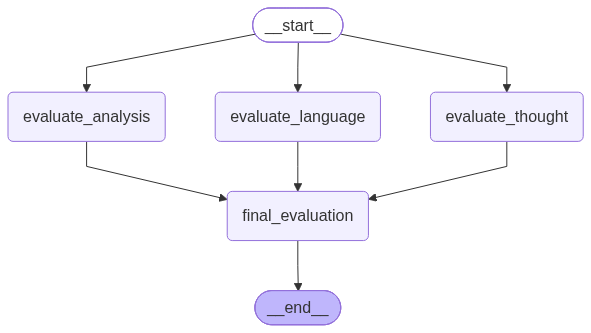

In [30]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())